## Configuration


In [598]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
participacions = pd.read_csv(RAIZ / "datos" / "clean" / "participacions.csv")
carreiras = pd.read_csv(RAIZ / "datos" / "clean" / "carreiras.csv").sort_values("orde")
participacions = participacions.merge(
    carreiras[["id_carrera", "orde"]], on="id_carrera", how="left", validate="many_to_one"
)
OUTPUT = RAIZ / "output"
OUTPUT.mkdir(exist_ok=True)

# Medidas auxiliares que usan varias preguntas
participacions["tam_carrera"] = participacions.groupby("id_carrera")["persoa_id"].transform("size")
participacions["posicion_relativa"] = participacions["puesto_general"] / participacions["tam_carrera"] 

participacions["total_sexo"] = participacions.groupby(["id_carrera", "sexo"])["persoa_id"].transform("size")
participacions["percentil"] = (
    (participacions["total_sexo"] - participacions["puesto_por_sexo"])
    / (participacions["total_sexo"] - 1)
).where(participacions["total_sexo"] > 1)         

In [599]:
print(participacions.head())
print(carreiras.head())

      persoa_id  id_carrera   tipo_inscripcion  \
0  fe5bb85dce0a  carrera_01         por_prueba   
1  538a30f9a5e7  carrera_01  inscrito_circuito   
2  1feaf06d7d2e  carrera_01         por_prueba   
3  e0fa7a0d4838  carrera_01  inscrito_circuito   
4  5c832ee098e4  carrera_01         por_prueba   

                  resultado_cruce sexo categoria  puesto_general  \
0  sin coincidencia en el listado    M       SNR               1   
1       coinciden nombre y dorsal    M       SNR               2   
2  sin coincidencia en el listado    M     SUB23               3   
3       coinciden nombre y dorsal    M       SNR               4   
4  sin coincidencia en el listado    M       MS1               5   

   puesto_por_sexo  puesto_por_categoria  tiempo_segundos estado_tiempo  orde  \
0              1.0                     1             1230        valido     1   
1              2.0                     2             1260        valido     1   
2              3.0                     1       

## Participación
1. Participantes por sexo en cada carreira e evolución ao longo do circuíto.


In [600]:

# unstack() hace un pivot , porque sino tendriamos dos indices que serian sexo e id_carrera 
# al hacerlo pasamos que el id_carrera sea columnas y el sexo el indice, y si no forzamos
participacion_agrupado = participacions.groupby(["id_carrera","sexo"])["persoa_id"].nunique().unstack()
print(participacion_agrupado)

sexo          F    M
id_carrera          
carrera_01  558  928
carrera_02  294  629
carrera_03  237  553
carrera_04  298  577
carrera_05  189  467
carrera_06  184  459


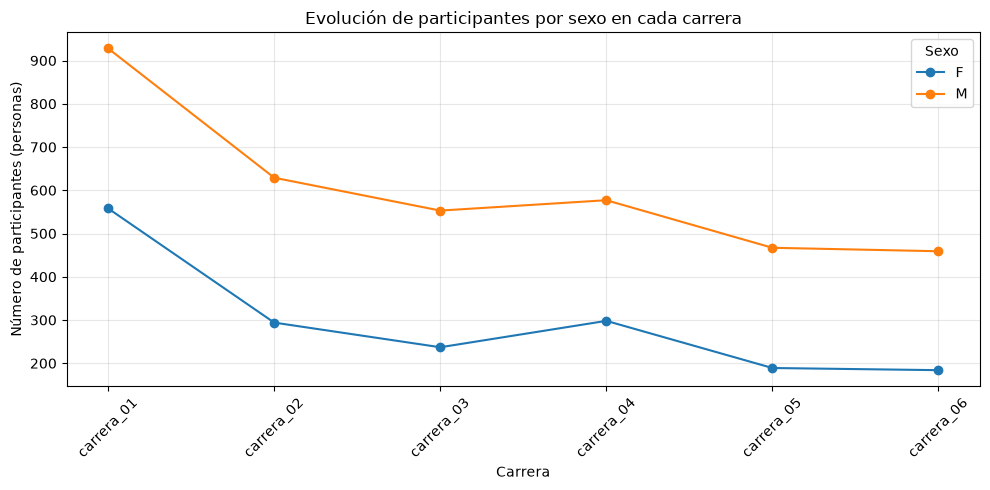

In [601]:
participacion_agrupado.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Evolución de participantes por sexo en cada carrera")
plt.xlabel("Carrera")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En esta gráfica observamos una disminucion progresiva de las personas masculinas a lo largo de la carerra, en cambio con respeto a la categoría femenina observamos tambien una disminucion con respecto a la primera y ultima carrera. En ambos casos vemos un ligero aumento justo en la carrera 4

2. Distribución por categorías de idade e diferenza entre sexos dentro de cada categoría.

In [602]:
participacions_idade = participacions.groupby(["categoria","sexo"])["persoa_id"].nunique().unstack()

print(participacions_idade)

sexo         F    M
categoria          
ESP          1    1
MS1        223  419
MS2        175  365
MS3         39  175
MS4         10   33
SNR        410  500
SUB20       21   18
SUB23       47   50


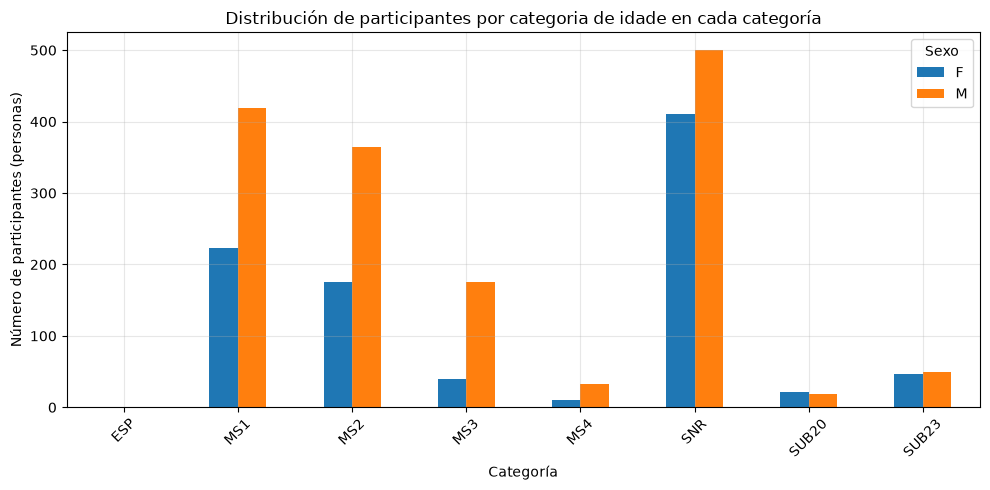

In [603]:
participacions_idade.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribución de participantes por categoria de idade en cada categoría")
plt.xlabel("Categoría")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Aqui observamos que la categoria con mas participantes en conjunto es "SNR". También en esta categoría es la que cuenta con mas femeninas y masculinos separados. En las categorías que empieza por MSX vemos que hay una grqn diferencia de cantidad de personas entre sexo

## Inscritos no circuíto e corredores por proba

1. En cada carreira, que porcentaxe de participantes están inscritos no circuíto e que porcentaxe corren por proba? Cambia ao longo do ano?

In [604]:
participacions_tipo = participacions.groupby(["id_carrera","tipo_inscripcion"])["persoa_id"].nunique().unstack().fillna(0)

participacions_tipo = participacions_tipo.drop(columns="no_resuelto")
# axis = 1 hace que opere horizontalmente
# Divide cada valor de una fila entre el total de esa carrera (axis = 0).
porcentajes = participacions_tipo.div(
    participacions_tipo.sum(axis=1), axis=0
) * 100

print(porcentajes.round(2))

tipo_inscripcion  inscrito_circuito  por_prueba
id_carrera                                     
carrera_01                    59.49       40.51
carrera_02                    78.33       21.67
carrera_03                    83.99       16.01
carrera_04                    72.60       27.40
carrera_05                    75.39       24.61
carrera_06                    76.26       23.74


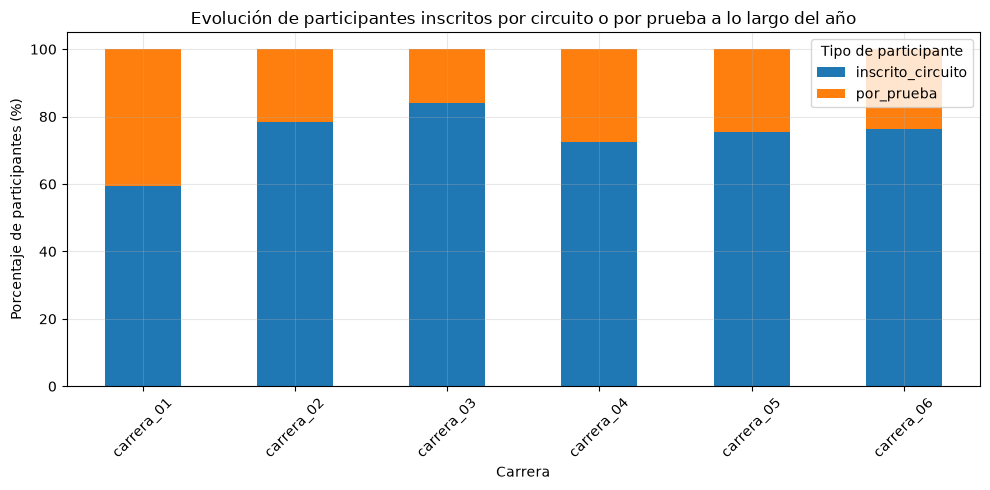

In [605]:
porcentajes.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Evolución de participantes inscritos por circuito o por prueba a lo largo del año")
plt.xlabel("Carrera")
plt.ylabel("Porcentaje de participantes (%)")
plt.legend(title="Tipo de participante")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2. En cantas carreiras participa de media unha persoa inscrita no circuíto? Cantas corren todas as carreiras, cantas abandonan e en que momento?

In [606]:
inscritos = participacions[
    participacions["tipo_inscripcion"] == "inscrito_circuito"
]

# Agrupamos por persona y miramos la columna id_carrera con las no repetidas, 
# entonces tenemos las carreras por personas
carrera_por_persona = inscritos.groupby(
    "persoa_id"
)["id_carrera"].nunique()

print("Cantidad de carreras de media que corren los inscritos en el circuito:",carrera_por_persona.mean())

# Total de carreras
total_carreras = carreiras["id_carrera"].nunique()

# Miramos si por carrera por personas es igual al numero total de carreras, para ver 
# cuantas personas completan todas las carreras.
completan = carrera_por_persona[
    carrera_por_persona == total_carreras
]

print("Personas que completan todas:", len(completan))

# Agrupamos los inscritos por persona, entonces tenemos una tabla por persona para ver el total de cada una en cada dato,
# Añadimos dos columnas nuevas una para ver la ultima carrera participada, y el numero de carreras participadas

ultima_participacion = inscritos.groupby(
    "persoa_id"
).agg(
    ultima_carrera=("orde", "max"),
    numero_carreras=("id_carrera", "nunique")
)

# Ultima carrera 
ultima_carrera_circuito = participacions["orde"].max()

# Abandono aparente , porque no podemos confirmar que por dejar de ir a una carrea hayan abandonado.
# Miramos si la ultima carrera de cada persona es menor a la ultima carrera de circuito.
abandonos_aparentes = ultima_participacion[
    ultima_participacion["ultima_carrera"] < ultima_carrera_circuito
]

# Agrupamos por la ultima carrera y contamos el numero de abandonos por su ultima carrea hecha
abandono_por_carrera = abandonos_aparentes.groupby(
    "ultima_carrera"
).size()

print("Personas que dejan de aparecer:", len(abandonos_aparentes))
print(abandono_por_carrera)


Cantidad de carreras de media que corren los inscritos en el circuito: 3.1782752902155886
Personas que completan todas: 150
Personas que dejan de aparecer: 721
ultima_carrera
1    149
2    112
3     99
4    181
5    180
dtype: int64


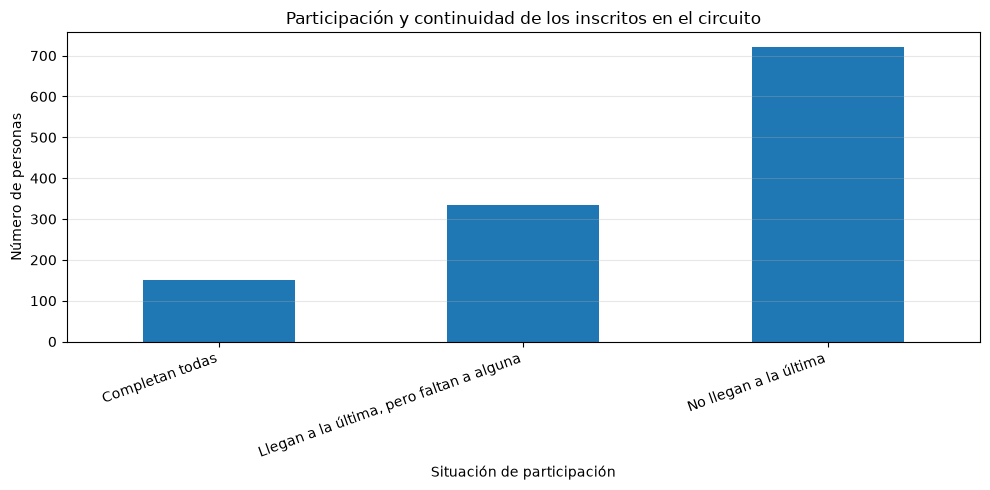

In [607]:
# Personas que completan todas las carreras
completan_todas = len(completan)

llegan_ultima = ultima_participacion[
    ultima_participacion["ultima_carrera"] == ultima_carrera_circuito
]

# Llegan a la última, pero no completan todas
llegan_pero_no_completan = (
    len(llegan_ultima) - completan_todas
)

# Dejan de aparecer antes de la última
no_llegan_ultima = len(abandonos_aparentes)

datos = pd.Series({
    "Completan todas": completan_todas,
    "Llegan a la última, pero faltan a alguna": llegan_pero_no_completan,
    "No llegan a la última": no_llegan_ultima
})

datos.plot(kind="bar", figsize=(10, 5))

plt.title("Participación y continuidad de los inscritos en el circuito")
plt.xlabel("Situación de participación")
plt.ylabel("Número de personas")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

3. Repiten as persoas que corren por proba? Hai quen corre varias carreiras sen inscribirse no circuíto?

In [608]:
tabla_tipo = participacions.groupby(["id_carrera", "tipo_inscripcion"]).size().unstack(fill_value=0)

resueltas = tabla_tipo[["inscrito_circuito", "por_prueba"]]

porcentajes = resueltas.div(resueltas.sum(axis=1), axis=0) * 100 
print(porcentajes.round(1).assign(no_resueltas=tabla_tipo["no_resuelto"]))


tipo_inscripcion  inscrito_circuito  por_prueba  no_resueltas
id_carrera                                                   
carrera_01                     59.5        40.5            35
carrera_02                     78.3        21.7            20
carrera_03                     84.0        16.0            14
carrera_04                     72.6        27.4            10
carrera_05                     75.4        24.6            13
carrera_06                     76.3        23.7             7


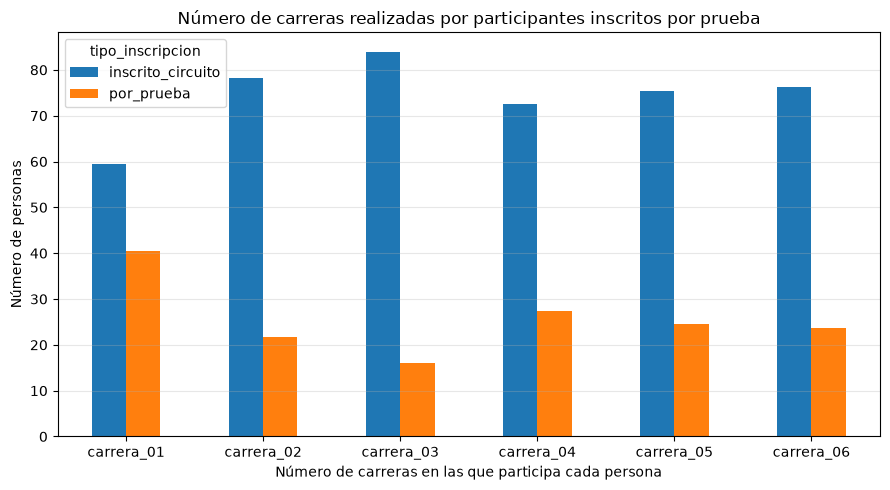

In [609]:

porcentajes.plot(kind="bar", figsize=(9, 5))

plt.title("Número de carreras realizadas por participantes inscritos por prueba")
plt.xlabel("Número de carreras en las que participa cada persona")
plt.ylabel("Número de personas")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Aqui vemos que si hay personas que repiten por prueba pero que la gran mayoría de inscritos por prueba corre una carrera. Aqui en esta gráfica vemos que tambien corren varias carreras sin inscribirse en el circuito.

4. Hai diferenzas por sexo e categoría entre inscritos no circuíto e corredores por proba?

In [610]:
circuito = inscritos.groupby(["sexo","categoria"])["persoa_id"].nunique().unstack()
por_proba = inscritos_proba.groupby(["sexo","categoria"])["persoa_id"].nunique().unstack()
tabla_tipo = participacions.groupby(["id_carrera", "tipo_inscripcion","sexo","categoria"]).size().unstack(fill_value=0)
print(tabla_tipo)
print(circuito)
print()
print(por_proba)

categoria                          MS1  MS2  MS3  MS4  SNR  SUB20  SUB23  ESP
id_carrera tipo_inscripcion  sexo                                            
carrera_01 inscrito_circuito F      65   65   21    5   84      2     13    0
                             M     169  165   84   20  151      6     14    1
           no_resuelto       F       6    3    0    1    6      0      0    0
                             M       5    3    4    0    3      0      1    0
           por_prueba        F      59   47   12    0  144     14     11    0
                             M      70   62   38    1  115      7      9    0
carrera_02 inscrito_circuito F      48   54   17    3   71      2     10    0
                             M     145  128   71   17  127      6     13    0
           no_resuelto       F       2    3    0    1    0      0      1    0
                             M       2    2    0    0    2      0      1    0
           por_prueba        F      20    9    1    0   46      

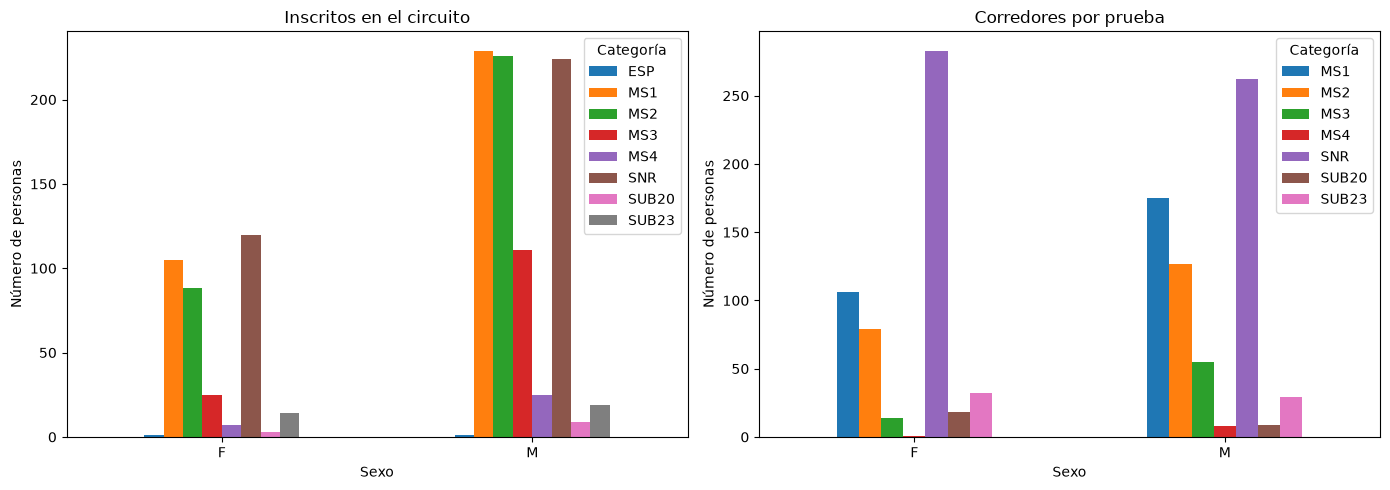

In [611]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

circuito.plot(kind="bar", ax=axes[0])
axes[0].set_title("Inscritos en el circuito")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Número de personas")
axes[0].legend(title="Categoría")
axes[0].tick_params(axis="x", rotation=0)

por_proba.plot(kind="bar", ax=axes[1])
axes[1].set_title("Corredores por prueba")
axes[1].set_xlabel("Sexo")
axes[1].set_ylabel("Número de personas")
axes[1].legend(title="Categoría")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Aqui vemos en la distribución por sexo y categoría entre los inscritos en el circuito y los corredores por prueba. Entre los inscritos en el circuito destacan las categorías MS1, MS2 y SNR, especialmente en hombres. En cambio, entre los corredores por prueba predomina claramente la categoría SNR siendo este la femenina mas predominante.

5. Os inscritos no circuíto quedan en mellores postos que os corredores por proba?

In [612]:
res = participacions[participacions["tipo_inscripcion"] != "no_resuelto"]
medias = res.groupby("tipo_inscripcion")["posicion_relativa"].agg(["count", "mean", "median"]).round(3)

print(medias)
medias_por_carrera = res.groupby(["id_carrera", "tipo_inscripcion"])["posicion_relativa"].median().unstack().round(3)
print(medias_por_carrera)

                   count  mean  median
tipo_inscripcion                      
inscrito_circuito   3833  0.47   0.458
por_prueba          1458  0.58   0.608
tipo_inscripcion  inscrito_circuito  por_prueba
id_carrera                                     
carrera_01                    0.428       0.596
carrera_02                    0.467       0.611
carrera_03                    0.497       0.566
carrera_04                    0.449       0.642
carrera_05                    0.469       0.598
carrera_06                    0.456       0.647


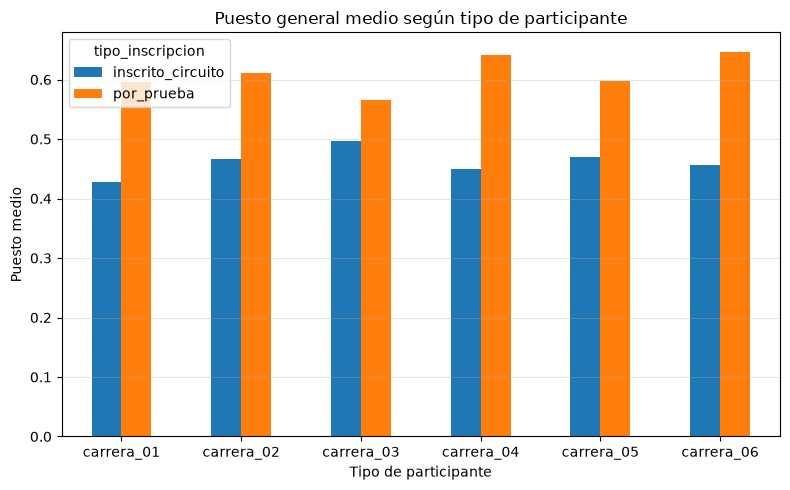

In [613]:
medias_por_carrera.plot(kind="bar", figsize=(8, 5))

plt.title("Puesto general medio según tipo de participante")
plt.xlabel("Tipo de participante")
plt.ylabel("Puesto medio")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Por media general sí, los corredores inscritos en ciruito tienen mejores puestos que los corredores de prueba.

## Rendemento

1. Distribución dos tempos por categoría e sexo.

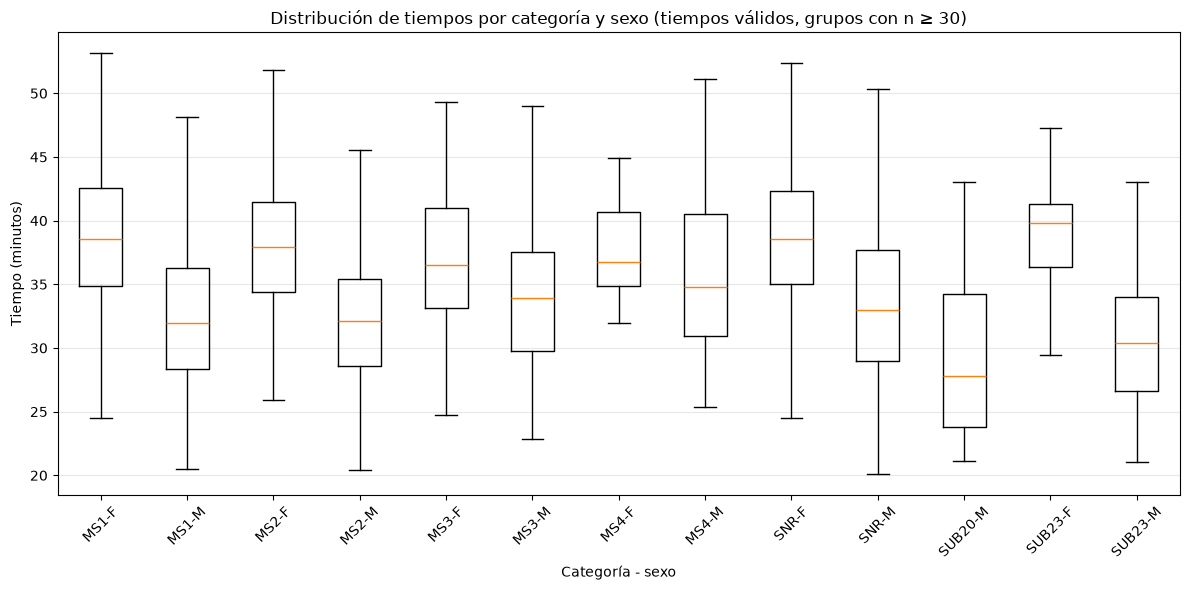

In [614]:
validos = participacions[participacions["estado_tiempo"] == "valido"].copy()
validos["minutos"] = validos["tiempo_segundos"] / 60
grupos = [(k, g["minutos"].to_numpy()) for k, g in validos.groupby(["categoria", "sexo"]) if len(g) >= 30]
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot([v for _, v in grupos], showfliers=False)
ax.set_xticks(range(1, len(grupos) + 1))
ax.set_xticklabels([f"{c}-{s}" for (c, s), _ in grupos], rotation=45)
ax.set_title("Distribución de tiempos por categoría y sexo (tiempos válidos, grupos con n ≥ 30)")
ax.set_xlabel("Categoría - sexo")
ax.set_ylabel("Tiempo (minutos)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Aqui vemos que el tiempo medio es normalmente la misma diferencia entre masculinos y femeninos, pero cabe destacar que la categoria "ESP" hay una diferencia mayor, también es que hay una persona de cada en esta categoría nada más

2. Quen mellora máis entre a primeira e a última carreira en que participa? Melloran máis os inscritos no circuíto?

In [615]:
participacions["total_sexo"] = participacions.groupby(
    ["id_carrera", "sexo"]
)["persoa_id"].transform("nunique")

# Calculamos el percentil relativo
participacions["percentil"] = (
    (participacions["total_sexo"] - participacions["puesto_por_sexo"]) /
    (participacions["total_sexo"] - 1)
)

# Evitamos divisiones entre cero
participacions.loc[
    participacions["total_sexo"] <= 1, "percentil"
] = float("nan")

participacions_ordenadas = participacions.sort_values("orde")

primera = participacions_ordenadas.groupby("persoa_id").first()
ultima = participacions_ordenadas.groupby("persoa_id").last()

mejoras = pd.DataFrame({
    "tipo_inscripcion": primera["tipo_inscripcion"],
    "percentil_primera": primera["percentil"],
    "percentil_ultima": ultima["percentil"],
})

mejoras["mejora_percentil"] = (
    mejoras["percentil_ultima"] -
    mejoras["percentil_primera"]
)


mejora_tipo = mejoras.groupby(
    "tipo_inscripcion"
) 

print(mejora_tipo.mean())

                   percentil_primera  percentil_ultima  mejora_percentil
tipo_inscripcion                                                        
inscrito_circuito           0.513500          0.491243         -0.022257
no_resuelto                 0.475036          0.475036          0.000000
por_prueba                  0.430090          0.431626          0.001536


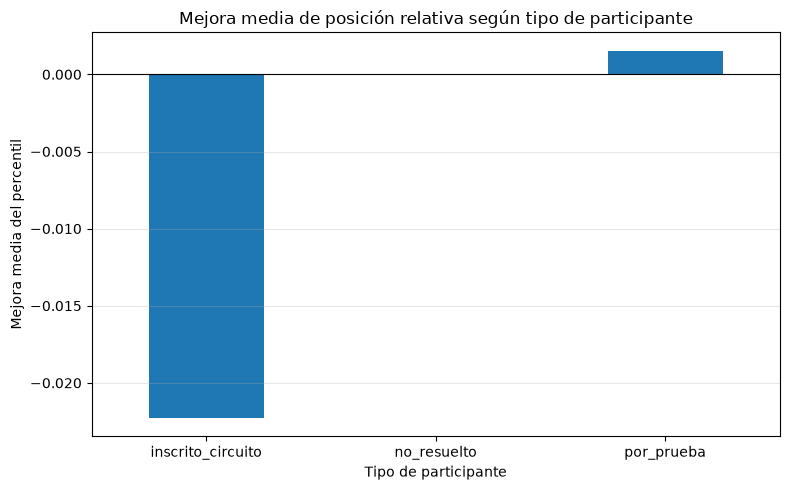

In [616]:
mejora_tipo = mejoras.groupby(
    "tipo_inscripcion"
)["mejora_percentil"].mean()

mejora_tipo.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Mejora media de posición relativa según tipo de participante")
plt.xlabel("Tipo de participante")
plt.ylabel("Mejora media del percentil")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Aqui vemos que que los inscritos en circuito mejoran mas sus tiempos en comparación con los inscritos en prueba

In [617]:

import pandas as pd
import os

# Copiamos los datos originales
prensa = participacions.copy()

# Tratamos los valores ausentes
prensa["sexo"] = prensa["sexo"].fillna("sen_dato")
prensa["categoria"] = prensa["categoria"].fillna("sen_dato")

# Agrupamos por carrera, sexo y categoría
prensa = prensa.groupby(
    ["id_carrera", "sexo", "categoria"],
    dropna=False
).agg(
    participantes=("persoa_id", "nunique")
).reset_index()

# Solo publicamos combinaciones con al menos 5 participantes
umbral = 5

grupos_suprimidos = prensa[prensa["participantes"] < umbral]

prensa_publica = prensa[
    prensa["participantes"] >= umbral
].copy()

# Ordenamos los resultados
prensa_publica = prensa_publica.sort_values(
    ["id_carrera", "sexo", "categoria"]
)

# Creamos la carpeta de salida
os.makedirs("../output", exist_ok=True)

# Guardamos el CSV público
prensa_publica.to_csv(
    "../output/prensa.csv",
    index=False,
    encoding="utf-8"
)

print("Participaciones originales:", len(participacions))
print("Grupos agregados:", len(prensa))
print("Grupos suprimidos:", len(grupos_suprimidos))
print("Grupos publicados:", len(prensa_publica))

print("\nCSV para prensa:")
print(prensa_publica)


Participaciones originales: 5390
Grupos agregados: 91
Grupos suprimidos: 12
Grupos publicados: 79

CSV para prensa:
    id_carrera sexo categoria  participantes
0   carrera_01    F       MS1            130
1   carrera_01    F       MS2            115
2   carrera_01    F       MS3             33
3   carrera_01    F       MS4              6
4   carrera_01    F       SNR            234
..         ...  ...       ...            ...
86  carrera_06    M       MS3             57
87  carrera_06    M       MS4             16
88  carrera_06    M       SNR            117
89  carrera_06    M     SUB20              6
90  carrera_06    M     SUB23             13

[79 rows x 4 columns]


In [618]:
inv = participacions.copy()

# Sexo generalizado
inv["sexo_generalizado"] = inv["sexo"].fillna("sen_dato")

# Categoria generalizada
cat = inv["categoria"].fillna("sen_dato")
inv["categoria_generalizada"] = cat.replace(
    {"MS1": "MASTER", "MS2": "MASTER", "MS3": "MASTER", "MS4": "MASTER",
     "SUB20": "SUB23", "ESP": "OUTRAS", "SNR": "OUTRAS", "NO": "OUTRAS"}
)


# posición en cuartiles dentro del sexo; el tiempo exacto no se publica y los estados
# poco frecuentes (revisar/invalido/ausente) se agrupan para que no singularicen a nadie

# Posicion y tiempo generalizados
inv["cuartil_posicion"] = (
    pd.cut(inv["percentil"], bins=[-0.01, 0.25, 0.5, 0.75, 1.0], labels=["Q4", "Q3", "Q2", "Q1"])
    .astype("string").fillna("sen_dato")
)
inv["estado_tiempo_gen"] = np.where(inv["estado_tiempo"].eq("valido"), "valido", "no_valido")

# Columnas para mirar y definir nuestro k-anonimato
QI = ["id_carrera", "sexo_generalizado", "categoria_generalizada", "tipo_inscripcion",
      "cuartil_posicion", "estado_tiempo_gen"]  

# Calculo de k-anonimato 
K_MIN = 5
def k_personas(df, qi):
    return df.groupby(qi, dropna=False)["persoa_id"].transform("nunique")   # personas, no filas

print("k mínimo inicial:", int(k_personas(inv, QI).min()))

# Aplicamos la generalizacion segun hace falta hasta que K llegue a nuestro umbral
for col, valor in [("cuartil_posicion", "sen_dato"),
                   ("categoria_generalizada", "TODAS"),
                   ("sexo_generalizado", "sen_dato")]:
    pequeno = k_personas(inv, QI) < K_MIN
    if not pequeno.any():
        break
    inv.loc[pequeno, col] = valor
    print(f"{col}: {int(pequeno.sum())} filas generalizadas")

# Si nos quedan filas sin llegar a nuestro umbral del k decidimos suprimirlas
residuo = k_personas(inv, QI) < K_MIN
print("filas suprimidas por k insuficiente:", int(residuo.sum()), "de", len(inv))
inv = inv[~residuo].copy()

# Miramos nuestro k mínimo final para comprobar
k_final = k_personas(inv, QI)
print("k mínimo final:", int(k_final.min()))
assert k_final.min() >= K_MIN

# Los datos a entregar
columnas = ["persoa_id", "id_carrera", "orde", "tipo_inscripcion", "sexo_generalizado",
            "categoria_generalizada", "cuartil_posicion", "estado_tiempo_gen"]
inv[columnas].to_csv(OUTPUT / "investigacion.csv", index=False, encoding="utf-8")

k mínimo inicial: 1
cuartil_posicion: 238 filas generalizadas
categoria_generalizada: 82 filas generalizadas
sexo_generalizado: 57 filas generalizadas
filas suprimidas por k insuficiente: 45 de 5390
k mínimo final: 5


In [619]:
organizacion = participacions.merge(
    carreiras[["id_carrera", "fecha"]], on="id_carrera", how="left", validate="many_to_one"
)[["persoa_id", "id_carrera", "orde", "fecha", "tipo_inscripcion", "sexo", "categoria"]]
organizacion = organizacion.sort_values(["persoa_id", "orde"])
organizacion.to_csv(OUTPUT / "organizacion.csv", index=False, encoding="utf-8")